# OSSE: North American Monsoon Convection

An observing system simulation experiment (OSSE) evaluates how well an observing system, real or planned, would observe a phenomenon, by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of **convection during the North American Monsoon**. The nature run is the 7-km [GEOS-5 Nature Run (G5NR)](https://gmao.gsfc.nasa.gov/global_mesoscale/7km-G5NR/). The *features* of interest are patches of very cold cloud tops over the American Southwest. The observing systems are the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites ([ATMS](ValidateImagerATMS.ipynb) and [CrIS](ValidateImagerCrIS.ipynb)) and two notional future sounders with finer resolution.

The experiment asks two questions about each feature:

1. **Is it observed?** Does a sounder's swath cover the feature, as in the ground-track analyses of earlier TAT-C studies?
2. **Is it resolved?** Is the feature at least a few footprints across where it is observed? The footprint of a cross-track scanner grows from its nadir value toward the swath edge, so this depends on where in the swath the feature falls.

The steps are:

1. configure the scenario and the nature run (G5NR);
2. define the features (contiguous cold cloud tops) in each 30-minute frame of the nature run;
3. define the sensors (swath parameters fitted to real data in the validation notebooks, and horizontal resolution);
4. compute the ground tracks (swaths) of the satellites over the study region with TAT-C;
5. determine whether each feature is observed and resolved by each sensor; and
6. generate a visualization and statistics.

The example is designed to run in a few minutes. It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`).

## Configure the Scenario

The study region is the American Southwest (31-38 N, 115-103 W: Arizona, New Mexico, and neighboring states), the core of the North American Monsoon, whose rains arrive between mid-June and mid-September. The scenario covers two days of the season at the Nature Run's 30-minute time-averaging interval, and is easily extended to the whole season by changing `start` and `duration` (the downloaded data and the computation scale linearly).

The Nature Run covers 15 May 2005 to 16 June 2007 and does not correspond to any real year, so the satellite orbits (those of 16 July 2026, from operational element sets) are paired with the nature run on the same calendar date of its first year. This is appropriate because the orbits are sun-synchronous, so their local solar times of observation do not depend on the date, and the Nature Run represents the diurnal cycle of the season.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box

DATA_DIR = Path("data") / "osse"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: the American Southwest, the core of the North American Monsoon
domain = box(-115, 31, -103, 38)
# the simulated orbits (a mid-season date) and the nature run (the same calendar date in the Nature Run's first year)
start = datetime(2026, 7, 16, tzinfo=timezone.utc)
nature_start = start.replace(year=2005)
duration = timedelta(days=2)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
n_frames = int(duration / frame_duration)

## Configure the Nature Run

The G5NR is a two-year global simulation by NASA's Global Modeling and Assimilation Office (GMAO) at a 7-km horizontal resolution, made for OSSEs (Gelaro et al., 2015). NASA serves it by OPeNDAP, which streams only the subset requested. This example uses the single-level, 30-minute time-averaged physics diagnostics at 0.0625 degrees (about 7 km), and reads the upwelling longwave flux at the top of the atmosphere (`lwtup`), a proxy for cloud-top temperature, and the convective precipitation rate (`preccon`). All frames for the study region are requested at once and saved in a local `data/osse` directory, so later runs are fast.

The 7-km collections are single-level (two-dimensional) diagnostics: the three-dimensional fields are available only coarsened to 0.5 degrees. This example therefore evaluates horizontal resolution only (see the limitations below).

In [2]:
import xarray as xr

G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"
GRID_SIZE = 0.0625  # deg

nature_file = DATA_DIR / f"g5nr_{nature_start:%Y%m%d}_{duration.days}d.nc"
if not nature_file.exists():
    # one request for all frames of the study region (a few minutes at most)
    minx, miny, maxx, maxy = domain.bounds
    with xr.open_dataset(G5NR_URL, decode_times=True) as remote:
        remote[["lwtup", "preccon"]].sel(
            time=slice(nature_start.replace(tzinfo=None), (nature_start + duration).replace(tzinfo=None)),
            lon=slice(minx, maxx),
            lat=slice(miny, maxy),
        ).load().to_netcdf(nature_file)
nature = xr.load_dataset(nature_file)
assert nature.sizes["time"] == n_frames
# each time stamp is the middle of its 30-minute averaging interval
assert (nature.time.values[0] - np.datetime64(nature_start.replace(tzinfo=None))) == np.timedelta64(15, "m")
nature

C:\Users\pgrogan1\AppData\Local\miniforge3\envs\tatc\lib\site-packages\xarray\coding\times.py:200: SerializationWarning: Ambiguous reference date string: 1-1-1 00:00:0.0. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0001-1-1 00:00:0.0). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)


C:\Users\pgrogan1\AppData\Local\miniforge3\envs\tatc\lib\site-packages\xarray\coding\times.py:200: SerializationWarning: Ambiguous reference date string: 1-1-1 00:00:0.0. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0001-1-1 00:00:0.0). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)


<xarray.Dataset> Size: 17MB
Dimensions:  (time: 96, lat: 113, lon: 193)
Coordinates:
  * time     (time) datetime64[ns] 768B 2005-07-16T00:15:00 ... 2005-07-17T23...
  * lat      (lat) float64 904B 31.0 31.06 31.12 31.19 ... 37.88 37.94 38.0
  * lon      (lon) float64 2kB -115.0 -114.9 -114.9 ... -103.1 -103.1 -103.0
Data variables:
    lwtup    (time, lat, lon) float32 8MB 314.9 315.9 314.4 ... 301.4 301.4
    preccon  (time, lat, lon) float32 8MB 0.0 0.0 0.0 ... 0.0 1.764e-08
Attributes:
    title:                2d,30-Minute,Time-Averaged,Single-Level,Full Resolu...
    Conventions:          COARDS\nGrADS
    dataType:             Grid
    history:              Mon Sep 28 16:07:28 EDT 2026 : imported by GrADS Da...
    extra_das_attribute:  This is an example of metadata added using a supple...

## Define the Environmental Features

Features are contiguous patches of grid cells whose upwelling longwave flux is below that of a 220 K blackbody (`5.67037e-8 * 220**4` W m-2, about 133 W m-2), that is, whose clouds are very cold and therefore very high, as in deep convection. Each patch in each frame is a feature. (A convective system that persists for several frames is counted in each, and a feature is a snapshot of it.) Patches of a single cell are discarded because they are not credibly resolved by the Nature Run, whose effective resolution is several grid cells.

For each feature, the notebook records its area, the diameter of a circle of the same area (its size), the area-weighted centroid, its coldest flux and highest convective precipitation rate, the total convective precipitation, and the solar hour at the centroid (the Sun's hour angle plus 12 hours, which is 12 at local solar noon).

In [3]:
import scipy.ndimage as ndi
from skyfield.api import wgs84

from tatc.constants import EARTH_MEAN_RADIUS, de421, timescale

THRESHOLD = 5.67037e-8 * 220**4  # W m-2, the upwelling longwave flux of a 220 K blackbody
MIN_CELLS = 2  # smaller features are not resolved by the Nature Run

lon, lat = nature.lon.values, nature.lat.values
lon2d, lat2d = np.meshgrid(lon, lat)
cell_area = (EARTH_MEAN_RADIUS * np.radians(GRID_SIZE)) ** 2 * np.cos(np.radians(lat2d))  # m^2

records, polygons = [], []
for frame in range(n_frames):
    lwtup = nature["lwtup"].isel(time=frame).values
    preccon = nature["preccon"].isel(time=frame).values
    labels, n_labels = ndi.label(lwtup < THRESHOLD)  # contiguous cells colder than the threshold
    if n_labels == 0:
        continue
    ids = np.arange(1, n_labels + 1)
    area = ndi.sum(cell_area, labels, ids)
    n_cells = ndi.sum(np.ones_like(lwtup), labels, ids).astype(int)
    # polygons are the unions of the cells, which are centered on the grid points
    j, i = np.nonzero(labels)
    order = np.argsort(labels[j, i], kind="stable")
    j, i = j[order], i[order]
    cells = shapely.box(
        lon[i] - GRID_SIZE / 2, lat[j] - GRID_SIZE / 2, lon[i] + GRID_SIZE / 2, lat[j] + GRID_SIZE / 2
    )
    for k, cluster in enumerate(np.split(cells, np.cumsum(n_cells)[:-1])):
        records.append(
            {
                "frame": frame,
                "n_cells": n_cells[k],
                "area_km2": area[k] / 1e6,
                "lon": ndi.sum(cell_area * lon2d, labels, ids[k]) / area[k],
                "lat": ndi.sum(cell_area * lat2d, labels, ids[k]) / area[k],
                "min_lwtup": ndi.minimum(lwtup, labels, ids[k]),
                "max_preccon": ndi.maximum(preccon, labels, ids[k]),
                "tot_preccon": ndi.sum(preccon * cell_area, labels, ids[k]),
            }
        )
        polygons.append(shapely.union_all(cluster))

features = gpd.GeoDataFrame(records, geometry=polygons, crs="EPSG:4326")
features = features[features.n_cells >= MIN_CELLS].reset_index(drop=True)
features["time"] = start + features.frame * frame_duration
features["diameter_km"] = np.sqrt(4 * features.area_km2 / np.pi)  # of a circle of equal area
# solar hour at the feature (hour angle of the Sun plus 12 hours) at the middle of the frame, in the Nature Run's year
solar_time = timescale.from_datetimes([nature_start + (frame + 0.5) * frame_duration for frame in features.frame])
features["solar_hour"] = (
    de421["earth"] + wgs84.latlon(features.lat.values, features.lon.values)
).at(solar_time).observe(de421["sun"]).apparent().hadec()[0].hours + 12
features[["time", "n_cells", "area_km2", "diameter_km", "lon", "lat", "min_lwtup", "max_preccon", "solar_hour"]].describe().round(2)

,n_cells,area_km2,diameter_km,lon,lat,min_lwtup,max_preccon,solar_hour
count,596.00,596.00,596.00,596.00,596.00,596.00,596.0,596.00
mean,35.38,1396.78,34.72,-109.72,35.14,127.66,0.0,15.54
std,51.94,2048.81,23.95,2.07,2.07,3.47,0.0,5.97
min,2.00,76.12,9.84,-114.50,31.00,115.96,0.0,0.15
25%,6.00,230.10,17.12,-111.44,33.39,125.39,0.0,13.20
50%,15.00,574.44,27.04,-110.10,35.49,128.25,0.0,17.14
75%,42.00,1644.76,45.76,-108.18,37.02,130.40,0.0,19.85
max,352.00,14112.45,134.05,-104.81,38.00,132.67,0.0,23.99


## Define the Sensors

**Platforms.** The current constellation of sounders is Suomi NPP, NOAA-20, and NOAA-21, three satellites in a sun-synchronous orbit with an ascending node of about 13:30 local time. Each carries both the Advanced Technology Microwave Sounder (ATMS) and the Cross-track Infrared Sounder (CrIS).

**Swaths.** Each instrument is a rectangular `PointedInstrument` whose cross-track field of view spans its scan positions, using the scan parameters fitted to NOAA-20 data in the validation notebooks ([ATMS](ValidateImagerATMS.ipynb) and [CrIS](ValidateImagerCrIS.ipynb)): the effective spacing between scan positions and the roll angle, and a scan perpendicular to the inertial velocity (`VelocityFrame.INERTIAL`) rather than to the ground track. The along-track field of view is tailored to the 30 s time step (`compute_along_track_field_of_view`), so that consecutive footprints tile the swath. NOAA-21 and Suomi NPP are assumed identical to NOAA-20.

**Resolution.** Each sensor has a horizontal resolution (the diameter of its footprint at nadir) and a vertical resolution (carried as an attribute of the sensor, but not yet used; see the limitations).

| Sensor | Horizontal | Vertical | Basis |
| --- | --- | --- | --- |
| ATMS | 32 km | 3 km | 2.2 degree beam of the temperature sounding channels at about 830 km, confirmed by the [ATMS validation](ValidateImagerATMS.ipynb) |
| CrIS | 14 km | 1 km | 0.963 degree field of view at about 830 km, confirmed by the [CrIS validation](ValidateImagerCrIS.ipynb) |
| Future MW | 10 km | 300 m | target of a future microwave sounder |
| Future IR | 3 km | 150 m | target of a future infrared sounder |

The vertical resolutions are nominal values, not confirmed by the validation notebooks (the geolocation data do not measure them) or by the published sources consulted, which give no single value because the vertical resolution of a retrieved profile depends on the channels, the scene, and the retrieval. To isolate the effect of resolution, the future sensors are assumed to fly on the same platforms with the same scans (swaths) as their heritage counterparts: the future microwave sounder shares the ATMS swath and the future infrared sounder shares the CrIS swath.

In [4]:
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import VelocityFrame, compute_along_track_field_of_view

# element sets (epoch 2026-07-16 00:00 UTC) from the JPSS TLE-AUX archive, as in the validation notebooks
tles = {
    "Suomi NPP": [
        "1 37849U 11061A   26197.00000000  .00000095  00000-0  44942-4 0  2449",
        "2 37849  98.7951 137.6822 0001041 201.8158  13.6707 14.19522526762525",
    ],
    "NOAA-20": [
        "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
        "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# scan parameters fitted to NOAA-20 data in the ATMS and CrIS validation notebooks: the number of scan positions,
# their spacing (deg), and the roll angle (deg, positive to the left); both scan perpendicular to the inertial velocity
scans = {
    "ATMS": {"positions": 96, "spacing": 1.112, "roll": 0.04},
    "CrIS": {"positions": 30, "spacing": 3.334, "roll": -0.093},
}
TIME_STEP = 30  # s, of the ground track


def swath_instrument(name):
    """A rectangular view spanning the scan positions, tailored to the time step (as validated for ATMS and CrIS)."""
    scan = scans[name]
    field_of_regard = (scan["positions"] - 1) * scan["spacing"]
    return PointedInstrument(
        name=name,
        field_of_regard=field_of_regard,
        cross_track_field_of_view=field_of_regard,
        along_track_field_of_view=compute_along_track_field_of_view(
            orbits["NOAA-20"].get_mean_altitude(), TIME_STEP, orbits["NOAA-20"].get_inclination()
        ),
        roll_angle=scan["roll"],
        is_rectangular=True,
        velocity_frame=VelocityFrame.INERTIAL,
    )


satellites = [
    Satellite(name=name, orbit=orbit, instruments=[swath_instrument("ATMS"), swath_instrument("CrIS")])
    for name, orbit in orbits.items()
]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# sensors: the scan (swath) they share, their horizontal resolution at nadir (km), and vertical resolution (m)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32, "vertical_m": 3000},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14, "vertical_m": 1000},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10, "vertical_m": 300},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3, "vertical_m": 150},
    ]
).set_index("sensor")
sensors

,swath,horizontal_km,vertical_m
sensor,,,
ATMS,ATMS,32,3000
CrIS,CrIS,14,1000
Future MW,ATMS,10,300
Future IR,CrIS,3,150


## Compute the Ground Tracks

`collect_ground_track` returns the footprint of each instrument at each time step, clipped to the study region (the `mask`), which are tabulated per frame and combined (`swaths`) to find the area each swath covers in each frame. Each satellite crosses the region on a few passes per day, so this is quick.

In [5]:
from tatc.analysis import collect_ground_track

times = [start + timedelta(seconds=TIME_STEP * (i + 0.5)) for i in range(int(duration.total_seconds() // TIME_STEP))]
tracks = collect_ground_track(satellites, times, instrument_index=None, mask=domain)
tracks = tracks[tracks.valid_obs].reset_index(drop=True)
tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
tracks["frame"] = ((tracks.time - start) // frame_duration).astype(int)
# the area swept by each swath (ATMS or CrIS) in each frame
swaths = tracks.groupby(["frame", "instrument"]).geometry.agg(shapely.union_all)
tracks.groupby(["satellite", "instrument"]).agg(footprints=("time", "size"), first=("time", "min"), last=("time", "max"))

footprints                     first  \
satellite instrument                                         
NOAA-20   ATMS                48 2026-07-16 08:26:15+00:00   
          CrIS                46 2026-07-16 08:26:15+00:00   
NOAA-21   ATMS                25 2026-07-16 09:12:15+00:00   
          CrIS                23 2026-07-16 09:12:15+00:00   
Suomi NPP ATMS                40 2026-07-16 08:06:45+00:00   
          CrIS                33 2026-07-16 08:07:15+00:00   

                                          last  
satellite instrument                            
NOAA-20   ATMS       2026-07-17 21:09:45+00:00  
          CrIS       2026-07-17 21:09:45+00:00  
NOAA-21   ATMS       2026-07-17 20:15:15+00:00  
          CrIS       2026-07-17 20:15:15+00:00  
Suomi NPP ATMS       2026-07-17 20:50:45+00:00  
          CrIS       2026-07-17 20:50:45+00:00

## Compute Observability and Resolution

A feature is **observed** by a swath if the swath footprint of some time step in its frame contains its centroid. The area of the feature inside the swath is also recorded (`obs_fraction`), though it is not used below. For each look at a feature, the satellite's slant range and zenith angle at the feature follow from the satellite position at the time of the footprint (TAT-C's orbit propagation) and the feature's location, and give the size of the sensor's footprint there: its angular size times the slant range along track, and longer by the secant of the zenith angle across track. The footprint diameter below is that of a circle of the same area (the geometric mean of the two sizes), which the validation notebooks confirmed against the reported viewing geometry of real data. If a feature is seen by several satellites, its best (smallest) footprint is used.

A feature is **resolved** if its diameter is at least `RESOLUTION_FACTOR` times its footprint diameter. The default of two footprints is a Nyquist-style criterion (a feature must span at least a couple of samples to be distinguished from its surroundings), and the sensitivity to it is shown below.

In [6]:
from pyproj import Transformer
from skyfield.framelib import itrs

RESOLUTION_FACTOR = 2  # a feature is resolved if its diameter is at least this many footprint diameters

TO_ECEF = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)


def up(lon, lat):
    """Geodetic up unit vector, stacked on the last axis."""
    lon, lat = np.radians(lon), np.radians(lat)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)


def footprint_diameter(slant_range, zenith, horizontal_km):
    """Equivalent diameter (km) of the footprint of a circular field of view whose nadir footprint has a diameter of
    horizontal_km: its angular size times the slant range along track, and longer by the secant of the zenith cross track."""
    along = slant_range * (horizontal_km * 1e3 / (REFERENCE_RANGE_KM * 1e3))
    return np.sqrt(along * along / np.cos(np.radians(zenith))) / 1e3


# looks: the footprints (of a satellite's instrument, at a time) that contain the centroid of a feature in the same frame
points = gpd.GeoDataFrame(
    {"feature": features.index, "frame": features.frame},
    geometry=gpd.points_from_xy(features.lon, features.lat),
    crs="EPSG:4326",
)
looks = gpd.sjoin(
    points,
    tracks[["frame", "satellite", "instrument", "time", "geometry"]].rename(columns={"frame": "frame_track"}),
    predicate="within",
)
looks = looks[looks.frame == looks.frame_track].drop(columns=["index_right", "frame_track"]).reset_index(drop=True)

# the viewing geometry (slant range and zenith angle) from the satellite position at the time of the footprint
looks["range_m"], looks["zenith"] = np.nan, np.nan
for name, group in looks.groupby("satellite"):
    sat_xyz = np.array(orbits[name].to_gp_orbit().get_orbit_track(list(group.time)).frame_xyz(itrs).m).T
    target = np.stack(TO_ECEF.transform(features.lon[group.feature], features.lat[group.feature], 0 * group.feature), axis=-1)
    line_of_sight = sat_xyz - target
    looks.loc[group.index, "range_m"] = np.linalg.norm(line_of_sight, axis=-1)
    looks.loc[group.index, "zenith"] = np.degrees(
        np.arccos(
            np.sum(line_of_sight * up(features.lon[group.feature], features.lat[group.feature]), axis=-1)
            / np.linalg.norm(line_of_sight, axis=-1)
        )
    )

results = []
for sensor, row in sensors.iterrows():
    # the best (smallest footprint) look at each feature
    sensor_looks = looks[looks.instrument == row.swath].copy()
    sensor_looks["footprint_km"] = footprint_diameter(sensor_looks.range_m, sensor_looks.zenith, row.horizontal_km)
    best = sensor_looks.sort_values("footprint_km").groupby("feature").first()
    result = features[["frame", "diameter_km", "area_km2", "tot_preccon", "solar_hour"]].copy()
    result["sensor"] = sensor
    result["looks"] = sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
    result["observed"] = result.looks > 0
    result["satellite"] = best.satellite
    result["zenith"] = best.zenith
    result["footprint_km"] = best.footprint_km
    result["resolved"] = result.observed & (result.diameter_km >= RESOLUTION_FACTOR * result.footprint_km)
    # the fraction of the feature's area inside the swath
    swath = swaths.reindex(list(zip(result.frame, [row.swath] * len(result)))).values
    result["obs_fraction"] = np.where(
        pd.isna(swath), 0.0, shapely.area(shapely.intersection(features.geometry.values, swath)) / shapely.area(features.geometry.values)
    )
    results.append(result)
results = pd.concat(results).reset_index().rename(columns={"index": "feature"})
results.groupby("sensor")[["observed", "resolved"]].sum().join(sensors).loc[sensors.index]

,observed,resolved,swath,horizontal_km,vertical_m
sensor,,,,,
ATMS,69,2,ATMS,32,3000
CrIS,60,21,CrIS,14,1000
Future MW,69,34,ATMS,10,300
Future IR,60,59,CrIS,3,150


## Generate a Visualization

The figure shows one frame, the one with the most features observed by ATMS that also has unobserved ones. Features are colored by whether each sensor resolves them (blue), observes but does not resolve them (orange), or does not observe them (faded, outside the swath). The underlying image is the nature run's upwelling longwave flux, whose dark areas are cold cloud tops.

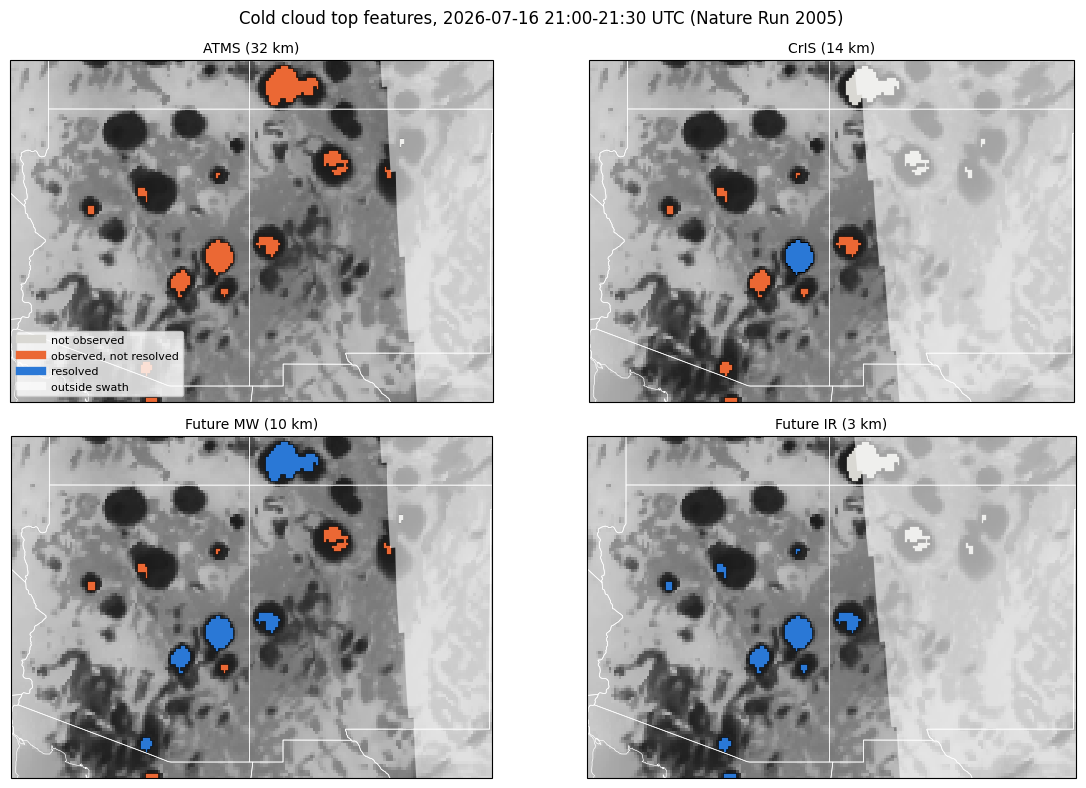

In [7]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# the frame, of those with features, with the largest number of unobserved features and the most observed features
frame_counts = results[results.sensor == "ATMS"].groupby("frame")["observed"].agg(["sum", "size"])
example = (frame_counts["sum"] * (frame_counts["size"] - frame_counts["sum"])).idxmax()
example_time = start + example * frame_duration
STATUS = {"not observed": "#d9d8d3", "observed, not resolved": "#eb6834", "resolved": "#2a78d6"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, sensor in zip(axes.ravel(), sensors.index):
    background = nature["lwtup"].isel(time=example)
    ax.pcolormesh(background.lon, background.lat, background, cmap="Greys_r", vmin=100, vmax=450, shading="auto", transform=ccrs.PlateCarree())
    members = results[(results.sensor == sensor) & (results.frame == example)]
    status = np.where(members.resolved, "resolved", np.where(members.observed, "observed, not resolved", "not observed"))
    for label, color in STATUS.items():
        selected = features.loc[members.feature[status == label]]
        if len(selected):
            selected.plot(ax=ax, facecolor=color, edgecolor="black", linewidth=0.4, transform=ccrs.PlateCarree())
    # fade the part of the study region outside the swath
    swath = swaths.get((example, sensors.loc[sensor, "swath"]))
    outside = domain if swath is None else domain.difference(swath)
    ax.add_geometries([outside], crs=ccrs.PlateCarree(), facecolor="white", edgecolor="none", alpha=0.6)
    ax.add_feature(cfeature.STATES, edgecolor="white", linewidth=0.5)
    ax.set_extent([domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]])
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
for label, color in STATUS.items():
    axes[0, 0].plot([], [], color=color, lw=6, label=label)
axes[0, 0].plot([], [], color="#ffffff", lw=6, alpha=0.6, label="outside swath")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=True)
fig.suptitle(f"Cold cloud top features, {example_time:%Y-%m-%d %H:%M}-{example_time + frame_duration:%H:%M} UTC (Nature Run {nature_start:%Y})")
fig.tight_layout()
plt.show()

## Generate Statistics

The table gives, for each sensor, the share of all features that are observed and resolved, the share of the total feature area and of the total convective precipitation that lies in resolved features, and the median footprint at the observed features.

In [8]:
total = {"features": len(features), "area": features.area_km2.sum(), "precipitation": features.tot_preccon.sum()}
summary = results.groupby("sensor").apply(
    lambda r: pd.Series(
        {
            "observed (% of features)": 100 * r.observed.mean(),
            "resolved (% of features)": 100 * r.resolved.mean(),
            "resolved (% of area)": 100 * r.area_km2[r.resolved].sum() / total["area"],
            "resolved (% of precipitation)": 100 * r.tot_preccon[r.resolved].sum() / total["precipitation"],
            "median footprint of observed (km)": r.footprint_km[r.observed].median(),
        }
    ),
    include_groups=False,
).loc[sensors.index]
summary.round(1)

,observed (% of features),resolved (% of features),resolved (% of area),resolved (% of precipitation),median footprint of observed (km)
sensor,,,,,
ATMS,11.6,0.3,1.4,2.5,49.5
CrIS,10.1,3.5,7.2,15.1,20.5
Future MW,11.6,5.7,10.6,21.0,15.5
Future IR,10.1,9.9,9.8,19.1,4.4


Over the two days, the study region has 596 features (the median is 27 km in diameter, and three quarters are smaller than 46 km). The sounders observe about 10 to 12% of them, because the three satellites are all in the same orbit plane and cross the region within about an hour (near 13:30 local time) on their afternoon passes and again about 12 hours later (near 01:30), whereas the features concentrate in the afternoon and evening (see the solar hour below); finer resolution does not change this, because the swaths are the same. Among the features observed, resolution matters a great deal: with a criterion of two footprints, ATMS resolves almost none of them (2 of 69), because the median footprint at the observed features (50 km, larger than its 32 km nadir value because features are observed away from nadir) exceeds the 27 km median feature. CrIS resolves a third (21 of 60), a future microwave sounder half (34 of 69), and a future infrared sounder nearly all (59 of 60).

Because the larger features (which are resolved first) are also the wetter ones, the resolved share of convective precipitation is greater than the resolved share of features (15% for CrIS, 21% for a future microwave sounder, and 19% for a future infrared sounder). The future infrared sounder resolves a slightly smaller share of precipitation than the future microwave sounder only because the CrIS swath is narrower than the ATMS swath, so it observes fewer features (60 vs. 69): once the resolution is fine enough, observability is limited by the swath.

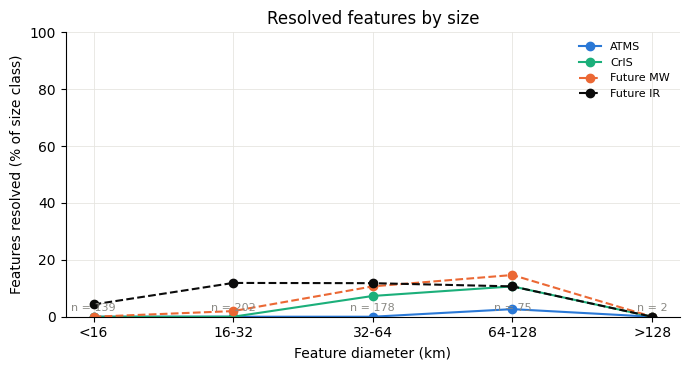

size_class,<16,16-32,32-64,64-128,>128
sensor,,,,,
ATMS,0.0,0.0,0.0,2.7,0.0
CrIS,0.0,0.0,7.3,10.7,0.0
Future MW,0.0,2.0,10.7,14.7,0.0
Future IR,4.3,11.9,11.8,10.7,0.0


In [9]:
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": INK}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

edges = np.array([0, 16, 32, 64, 128, np.inf])
labels = ["<16", "16-32", "32-64", "64-128", ">128"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)
by_size = results.groupby(["sensor", "size_class"], observed=False).resolved.mean().unstack().loc[sensors.index] * 100
counts = results[results.sensor == "ATMS"].groupby("size_class", observed=False).size()

fig, ax = plt.subplots(figsize=(7, 3.8))
for sensor in sensors.index:
    ax.plot(labels, by_size.loc[sensor], marker="o", color=SENSOR_COLORS[sensor], ls=SENSOR_STYLES[sensor], label=sensor)
ax.set(xlabel="Feature diameter (km)", ylabel="Features resolved (% of size class)", title="Resolved features by size", ylim=(0, 100))
ax.legend(frameon=False, fontsize=8)
for x, n in zip(labels, counts):
    ax.annotate(f"n = {n}", (x, 2), ha="center", fontsize=8, color=GRAY)
fig.tight_layout()
plt.show()
by_size.round(1)

Resolution matters most for the smaller features. The shares are of all features in each size class, so they also reflect how many of them are observed. A future infrared sounder resolves 4% of the features smaller than 16 km, which no other sensor resolves, and 11 to 12% of those from 16 to 128 km (about its overall observed share). A future microwave sounder resolves none below 16 km and 2% of those from 16 to 32 km, but 11 to 15% above 32 km. CrIS resolves 7 to 11% of those from 32 to 128 km, and ATMS only 3% of those from 64 to 128 km.

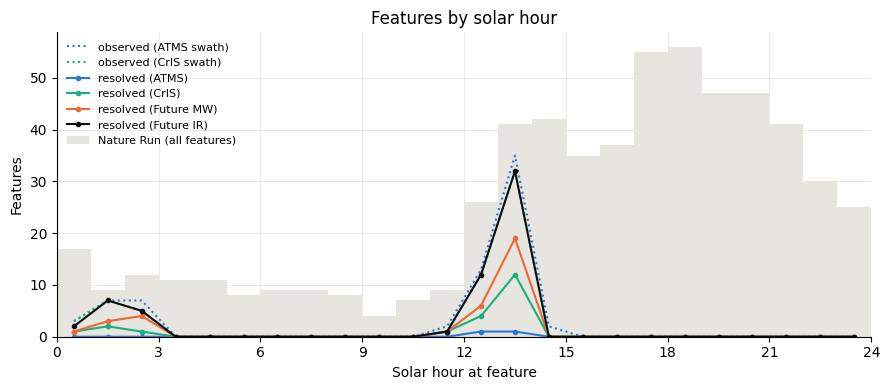

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 25, 1)
nature_hist, _ = np.histogram(features.solar_hour, bins)
ax.bar(bins[:-1] + 0.5, nature_hist, width=1, color="#e6e5e0", label="Nature Run (all features)")
for swath, style, color in [("ATMS", ":", BLUE), ("CrIS", ":", AQUA)]:
    r = results[results.sensor == swath]
    hist, _ = np.histogram(r.solar_hour[r.observed], bins)
    ax.plot(bins[:-1] + 0.5, hist, ls=":", color=color, label=f"observed ({swath} swath)")
for sensor in sensors.index:
    r = results[results.sensor == sensor]
    hist, _ = np.histogram(r.solar_hour[r.resolved], bins)
    ax.plot(bins[:-1] + 0.5, hist, ls="-", marker="o", ms=3, color=SENSOR_COLORS[sensor], label=f"resolved ({sensor})")
ax.set(xlabel="Solar hour at feature", ylabel="Features", title="Features by solar hour", xlim=(0, 24))
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The solar hour of the features shows when the sampling gap arises. Features are most frequent in the late afternoon and evening (about 17 to 21 solar hours), after the satellites' afternoon pass (near 13:30), which samples the developing convection, and well before their next pass (near 01:30), which samples the decaying convection. A constellation with a different distribution of local times (for example, satellites in other orbit planes) would observe more of the features, independently of resolution.

In [11]:
# sensitivity to the resolution criterion: the share of features resolved if their diameter must be at least N footprints
sensitivity = pd.DataFrame(
    {
        f"N = {n}": results.groupby("sensor").apply(
            lambda r: 100 * (r.observed & (r.diameter_km >= n * r.footprint_km)).mean(), include_groups=False
        )
        for n in (1, 2, 3)
    }
).loc[sensors.index]
sensitivity.round(1)

,N = 1,N = 2,N = 3
sensor,,,
ATMS,3.2,0.3,0.0
CrIS,7.7,3.5,2.0
Future MW,10.1,5.7,3.7
Future IR,10.1,9.9,9.6


Each sensor resolves fewer features with a stricter criterion (more footprints across a feature). The ranking of the sensors does not depend on it, but the differences between them do: a future infrared sounder is largely insensitive to it, whereas the resolved share of a future microwave sounder falls from 10% to 4% as the criterion tightens from one to three footprints.

## Limitations

* **Vertical resolution is not evaluated.** The 7-km Nature Run provides single-level fields only, so there is no vertical structure of features at its full resolution (the three-dimensional fields are coarsened to 0.5 degrees). The vertical resolutions of the sensors are carried in the `sensors` table as a placeholder. Evaluating them would require a definition of the vertical extent of a feature (for example, the depth between the cloud top, found from the 0.5 degree temperature profile, and the freezing level).
* **Resolution is geometric.** A sounder's resolution depends on its channels, the retrieval, and the scene, and the nominal footprint is used here, without modeling the sampling or response (point spread function) of each footprint, the overlap of neighbouring footprints, or the gaps between the views of CrIS.
* **Infrared sounders do not see through cloud.** Cold cloud tops, the features here, are observed by CrIS at their tops but, unlike microwave sounders, it does not observe the atmosphere beneath. This is not modeled.
* **The future sensors are assumed.** They share the swaths and platforms of ATMS and CrIS and a nominal resolution. Their own swaths, orbits, and constellations are open design variables of a trade study.
* **One realization.** Two days of one nature run year are a small sample. Extend `duration` and `start` to the whole season (mid-June to mid-September) and other years of the Nature Run for statistics.
* **Features are snapshots.** A convective system that persists is a feature in each 30-minute frame, and the features of a frame are not tracked from frame to frame.
* **The Nature Run is not reality.** Its convection is simulated and its feature statistics differ from those observed, so the results show the effect of the observing systems on a nature run, which is the point of an OSSE, rather than a forecast of real observations.